# **Food Delivery Time Prediction**

In [2]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import  root_mean_squared_error,r2_score,mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import  Pipeline
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder,OneHotEncoder

In [3]:
# load the data 
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\Food_Delivery_Time_Prediction.csv")

In [4]:
data.head()

,Order_ID,Order_Date,Order_Hour,Day_of_Week,Is_Weekend,Is_Festival,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,...,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Average_Speed_kmph,Delivery_Priority,Time_taken_min
0,ORD000001,2025-10-28,8,Tuesday,0,0,Clear,CBD,Commercial,Scooter,...,1,Medium,23,30.55,Long,Moderate,15,28.7,Normal,91
1,ORD000002,2025-09-26,12,Friday,0,0,Rain,CBD,CBD,Scooter,...,3,Medium,11,2.25,Short,Moderate,17,23.3,Normal,21
2,ORD000003,2025-01-26,18,Sunday,1,0,Clear,Residential,Residential,Scooter,...,1,Low,31,10.15,Long,Moderate,8,28.9,Normal,52
3,ORD000004,2025-11-19,12,Wednesday,0,0,Cloudy,Residential,Industrial,Bike,...,3,Medium,19,26.33,Long,Low,9,41.4,Normal,59
4,ORD000005,2025-08-04,18,Monday,0,0,Rain,Industrial,Residential,Bike,...,1,Medium,7,30.48,Long,Moderate,8,31.7,Normal,75


In [5]:
data.tail()

,Order_ID,Order_Date,Order_Hour,Day_of_Week,Is_Weekend,Is_Festival,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,...,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Average_Speed_kmph,Delivery_Priority,Time_taken_min
49995,ORD049996,2025-03-08,14,Saturday,1,0,Fog,Industrial,Industrial,Electric Scooter,...,1,Medium,25,33.67,Long,Low,4,28.6,Normal,94
49996,ORD049997,2025-10-23,8,Thursday,0,0,Clear,Suburban,Residential,Bike,...,4,Medium,35,15.92,Long,Low,5,44.0,Normal,54
49997,ORD049998,2025-10-24,7,Friday,0,0,Storm,Residential,CBD,Scooter,...,1,Low,9,19.38,Long,Low,9,23.7,Normal,66
49998,ORD049999,2025-03-16,20,Sunday,1,0,Clear,Residential,CBD,Scooter,...,2,Medium,26,30.92,Long,Moderate,7,28.4,Priority,92
49999,ORD050000,2025-10-21,21,Tuesday,0,0,Rain,Residential,Residential,Bike,...,3,Low,24,35.51,Long,Moderate,8,29.5,Normal,103


In [6]:
print(f"Data Shape: {data.shape}")
print(f'Duplicate Values {data.duplicated().sum()}')
print(f'Total Missing values: {data.isnull().sum().sum()}')

Data Shape: (50000, 24)
Duplicate Values 0
Total Missing values: 0


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Order_ID                    50000 non-null  str    
 1   Order_Date                  50000 non-null  str    
 2   Order_Hour                  50000 non-null  int64  
 3   Day_of_Week                 50000 non-null  str    
 4   Is_Weekend                  50000 non-null  int64  
 5   Is_Festival                 50000 non-null  int64  
 6   Weather                     50000 non-null  str    
 7   Pickup_Zone                 50000 non-null  str    
 8   Dropoff_Zone                50000 non-null  str    
 9   Vehicle_Type                50000 non-null  str    
 10  Rider_Experience_Years      50000 non-null  float64
 11  Rider_Rating                50000 non-null  float64
 12  Restaurant_Rating           50000 non-null  float64
 13  Cuisine_Type                50000 non-null

- Droping `order_id` , `Order_Date` as these are irrelevent for our model prediction.

In [8]:
# drop order-id
data = data.drop(columns=['Order_ID','Order_Date'])

## **Univariate Analysis**

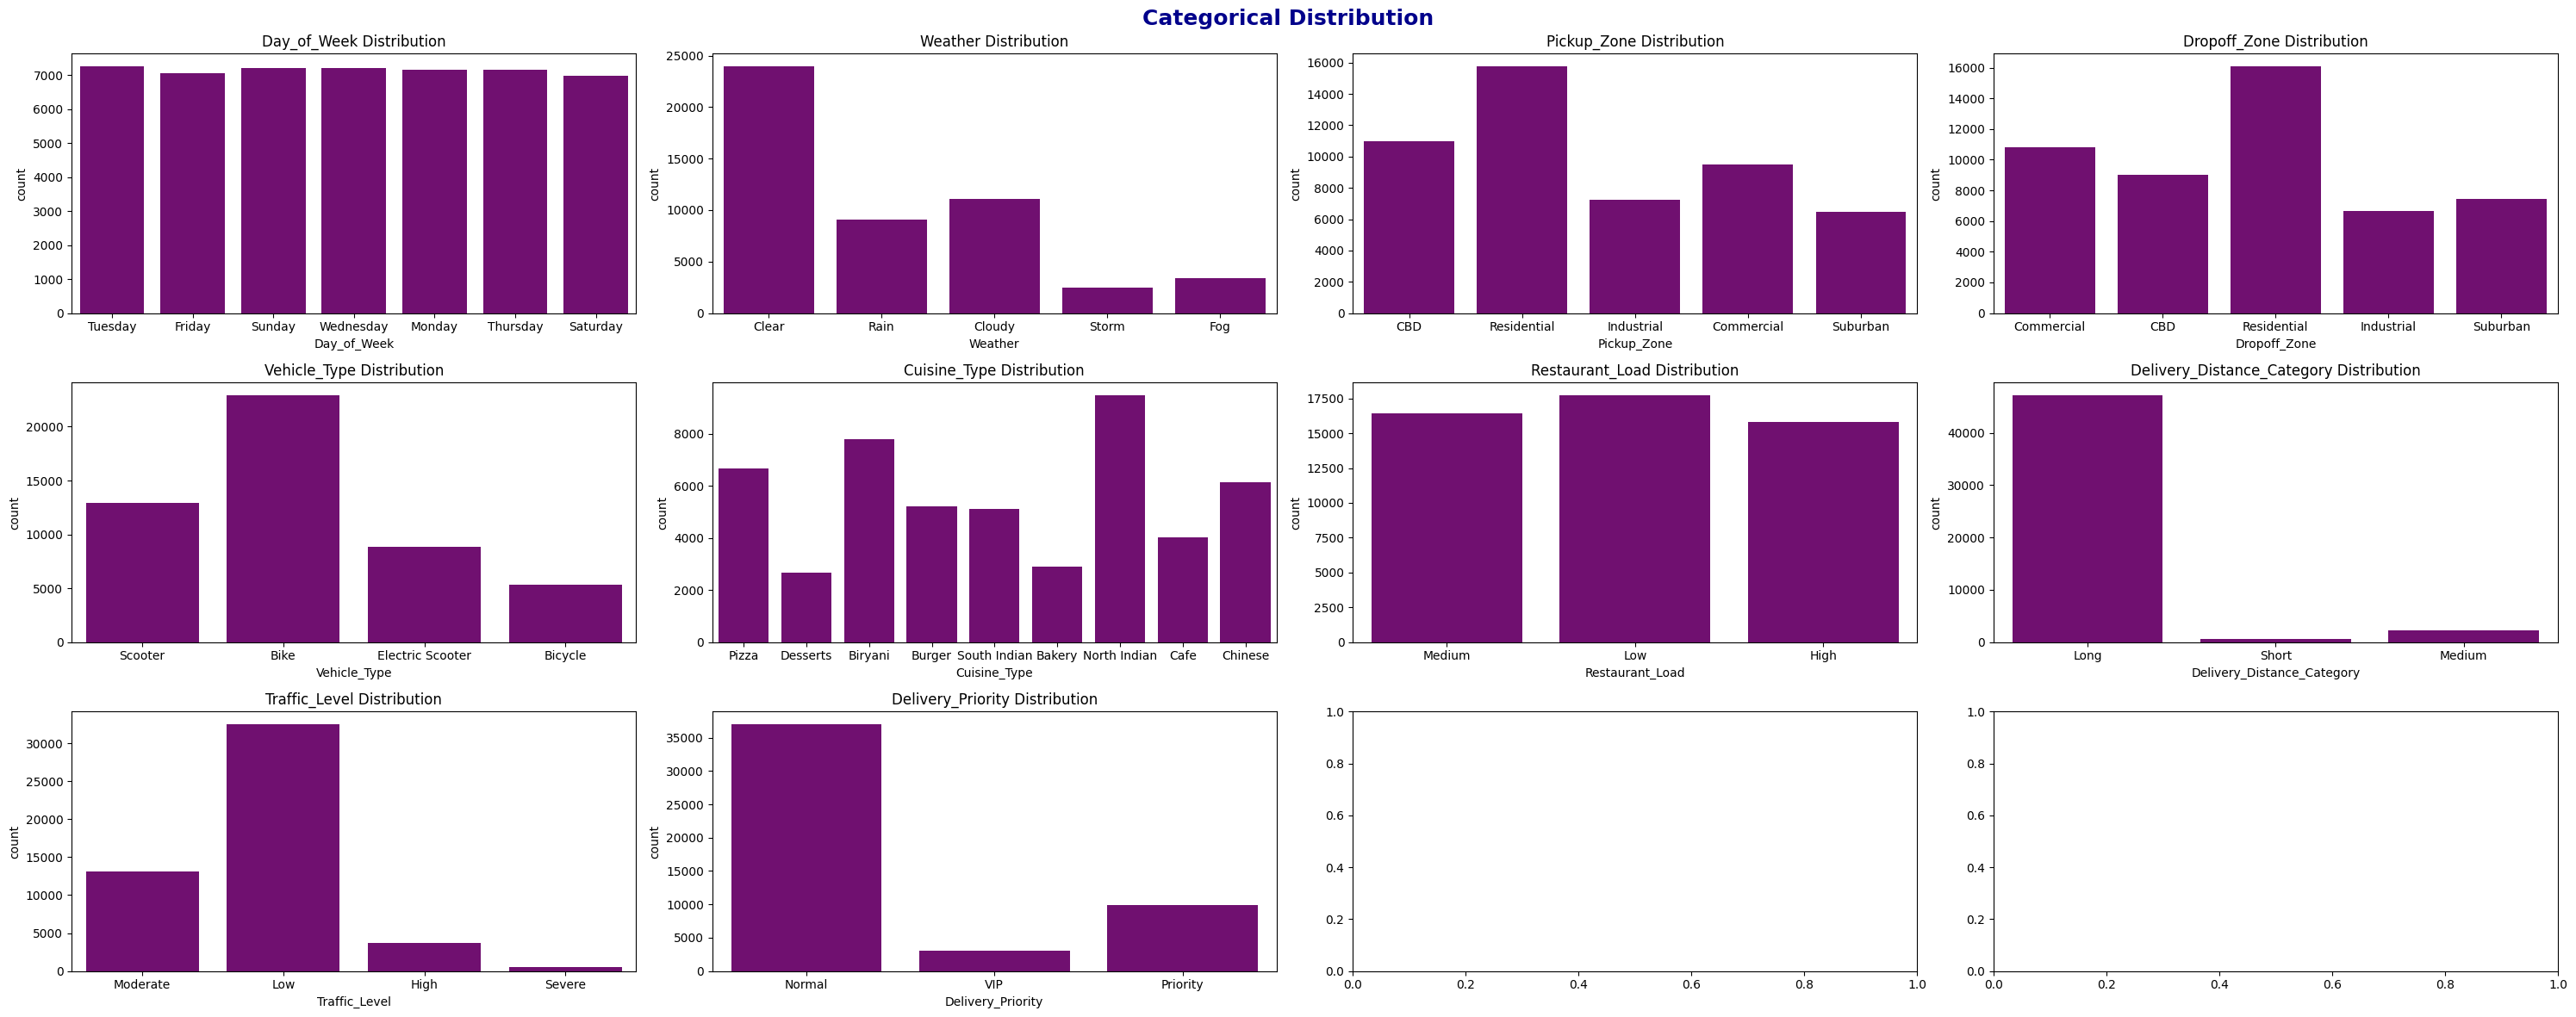

In [9]:
cat_cols = data.select_dtypes(include='str').columns.to_list()

fig , axes = plt.subplots(3,4,figsize =(30,12))
axes = axes.flatten()
plt.suptitle('Categorical Distribution',color = 'darkblue',fontweight = 'bold',fontsize=18)
for i,col in enumerate(cat_cols):
    sns.countplot(x=data[col],ax=axes[i],color='purple')
    axes[i].set_title(f'{col} Distribution')
plt.tight_layout()
plt.show()

- dividing categorical columns in ordinal and nominal.

In [10]:
data.select_dtypes(include='str').columns.to_list()

['Day_of_Week',
 'Weather',
 'Pickup_Zone',
 'Dropoff_Zone',
 'Vehicle_Type',
 'Cuisine_Type',
 'Restaurant_Load',
 'Delivery_Distance_Category',
 'Traffic_Level',
 'Delivery_Priority']

In [11]:
ord_cat = ['Traffic_Level','Delivery_Priority','Delivery_Distance_Category','Delivery_Priority']
nom_cat = [cols for cols in cat_cols if cols not in ord_cat]
print(nom_cat)

['Day_of_Week', 'Weather', 'Pickup_Zone', 'Dropoff_Zone', 'Vehicle_Type', 'Cuisine_Type', 'Restaurant_Load']


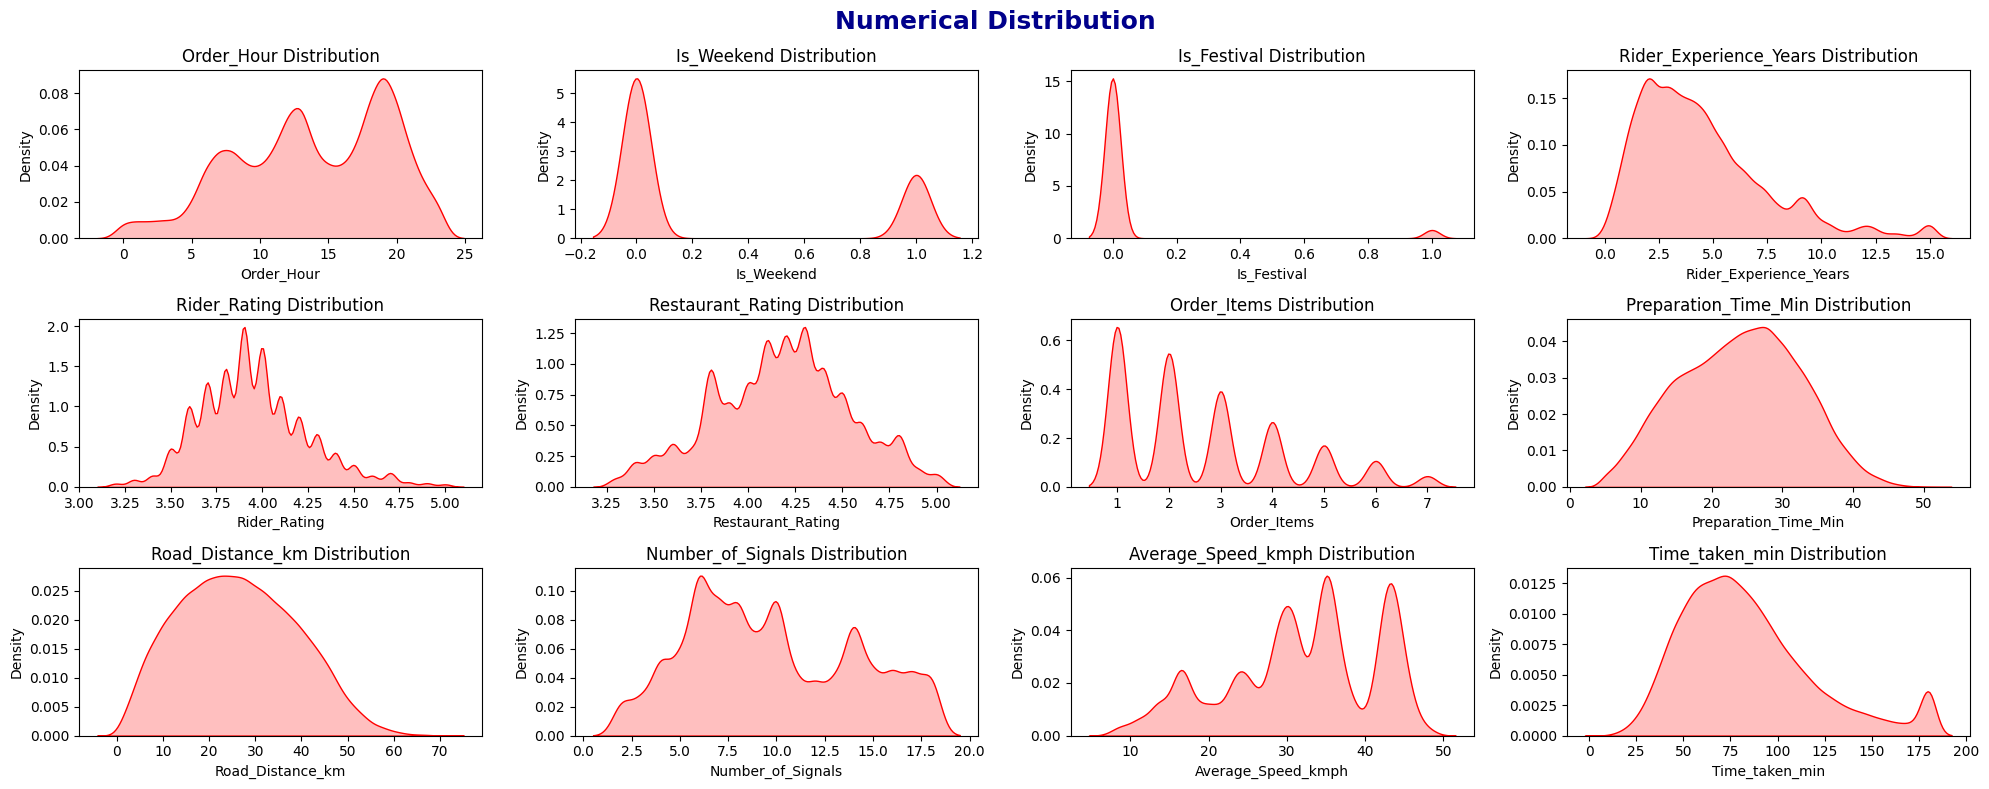

In [12]:
num_cols = data.select_dtypes(include='number').columns.to_list()
fig , axes = plt.subplots(3,4,figsize =(20,8))
axes = axes.flatten()
plt.suptitle('Numerical Distribution',color = 'darkblue',fontweight = 'bold',fontsize=18)
for i,col in enumerate(num_cols):
    sns.kdeplot(data[col],ax=axes[i],color='red',fill=True)
    axes[i].set_title(f'{col} Distribution')
plt.tight_layout()
plt.show()

## **Bivariate Analysis**

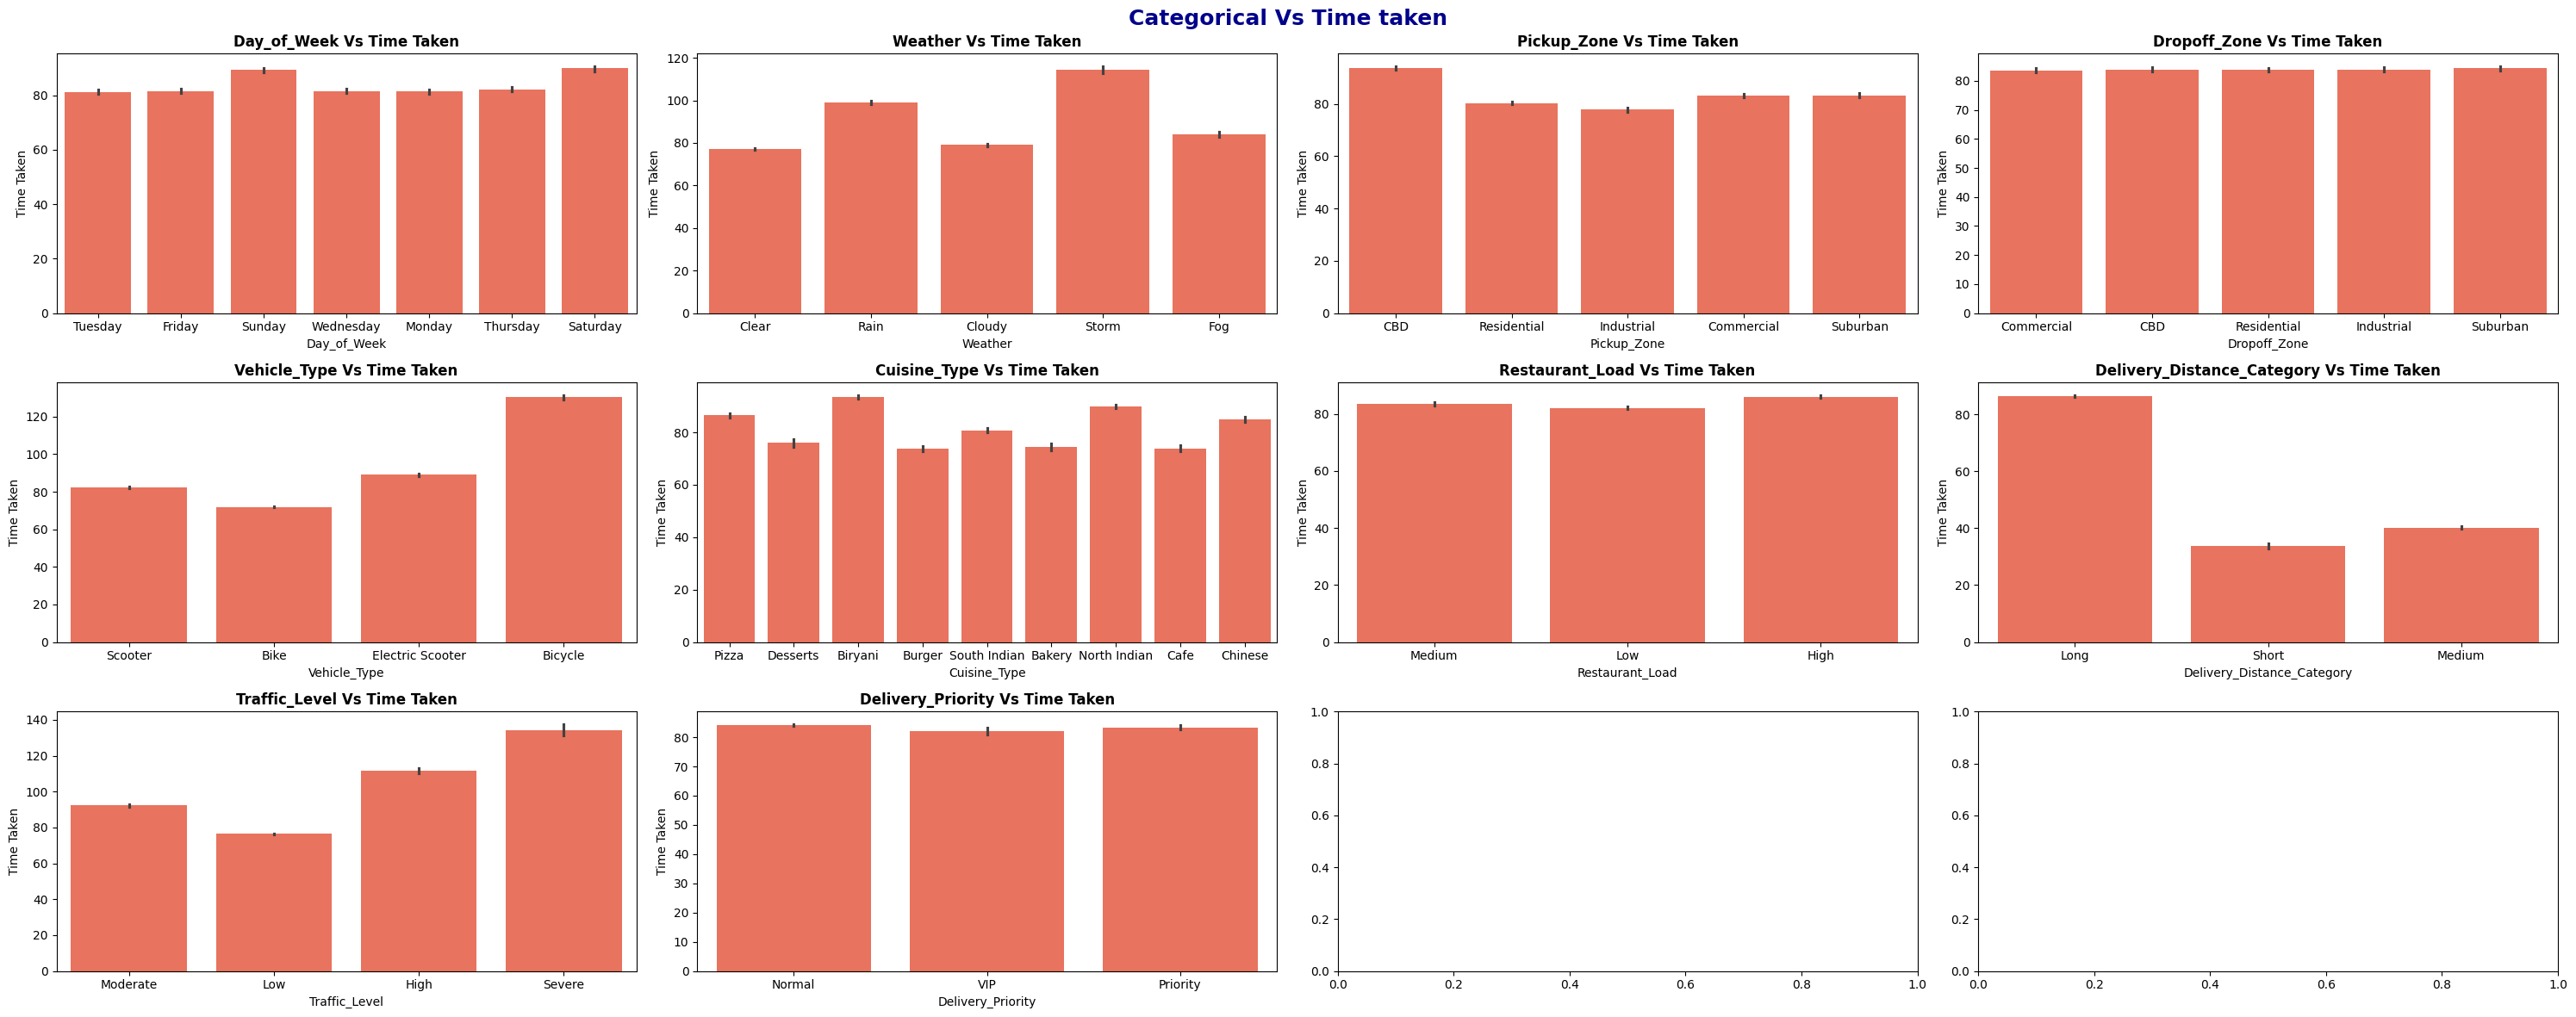

In [13]:
# categorical conclumns vs Target 
fig , axes = plt.subplots(3,4,figsize =(30,12))
axes = axes.flatten()
plt.suptitle('Categorical Vs Time taken',color = 'darkblue',fontweight = 'bold',fontsize=18)
for i,col in enumerate(cat_cols):
    sns.barplot(x=data[col],y=data['Time_taken_min'],ax=axes[i],color='tomato')
    axes[i].set_title(f'{col} Vs Time Taken',fontweight = 'bold')
    axes[i].set_ylabel('Time Taken')
plt.tight_layout()
plt.show()

**Inferance:**
- Strong predictors:  `Vehicle_Type`  (Bicycle ~120 min vs Bike ~70 min),  `Traffic_Level`  (Severe ~125 min vs Low ~75 min),  Delivery_Distance_Category  (Long ~80 min vs Short ~30 min)
- Moderate predictors:  Weather  (Storm highest),  Pickup_Zone  (CBD highest),  Cuisine_Type  (Biryani highest)
- Weak predictors:  `Day_of_Week` ,  `Restaurant_Load` ,  `Delivery_Priority` (all categories show similar times)

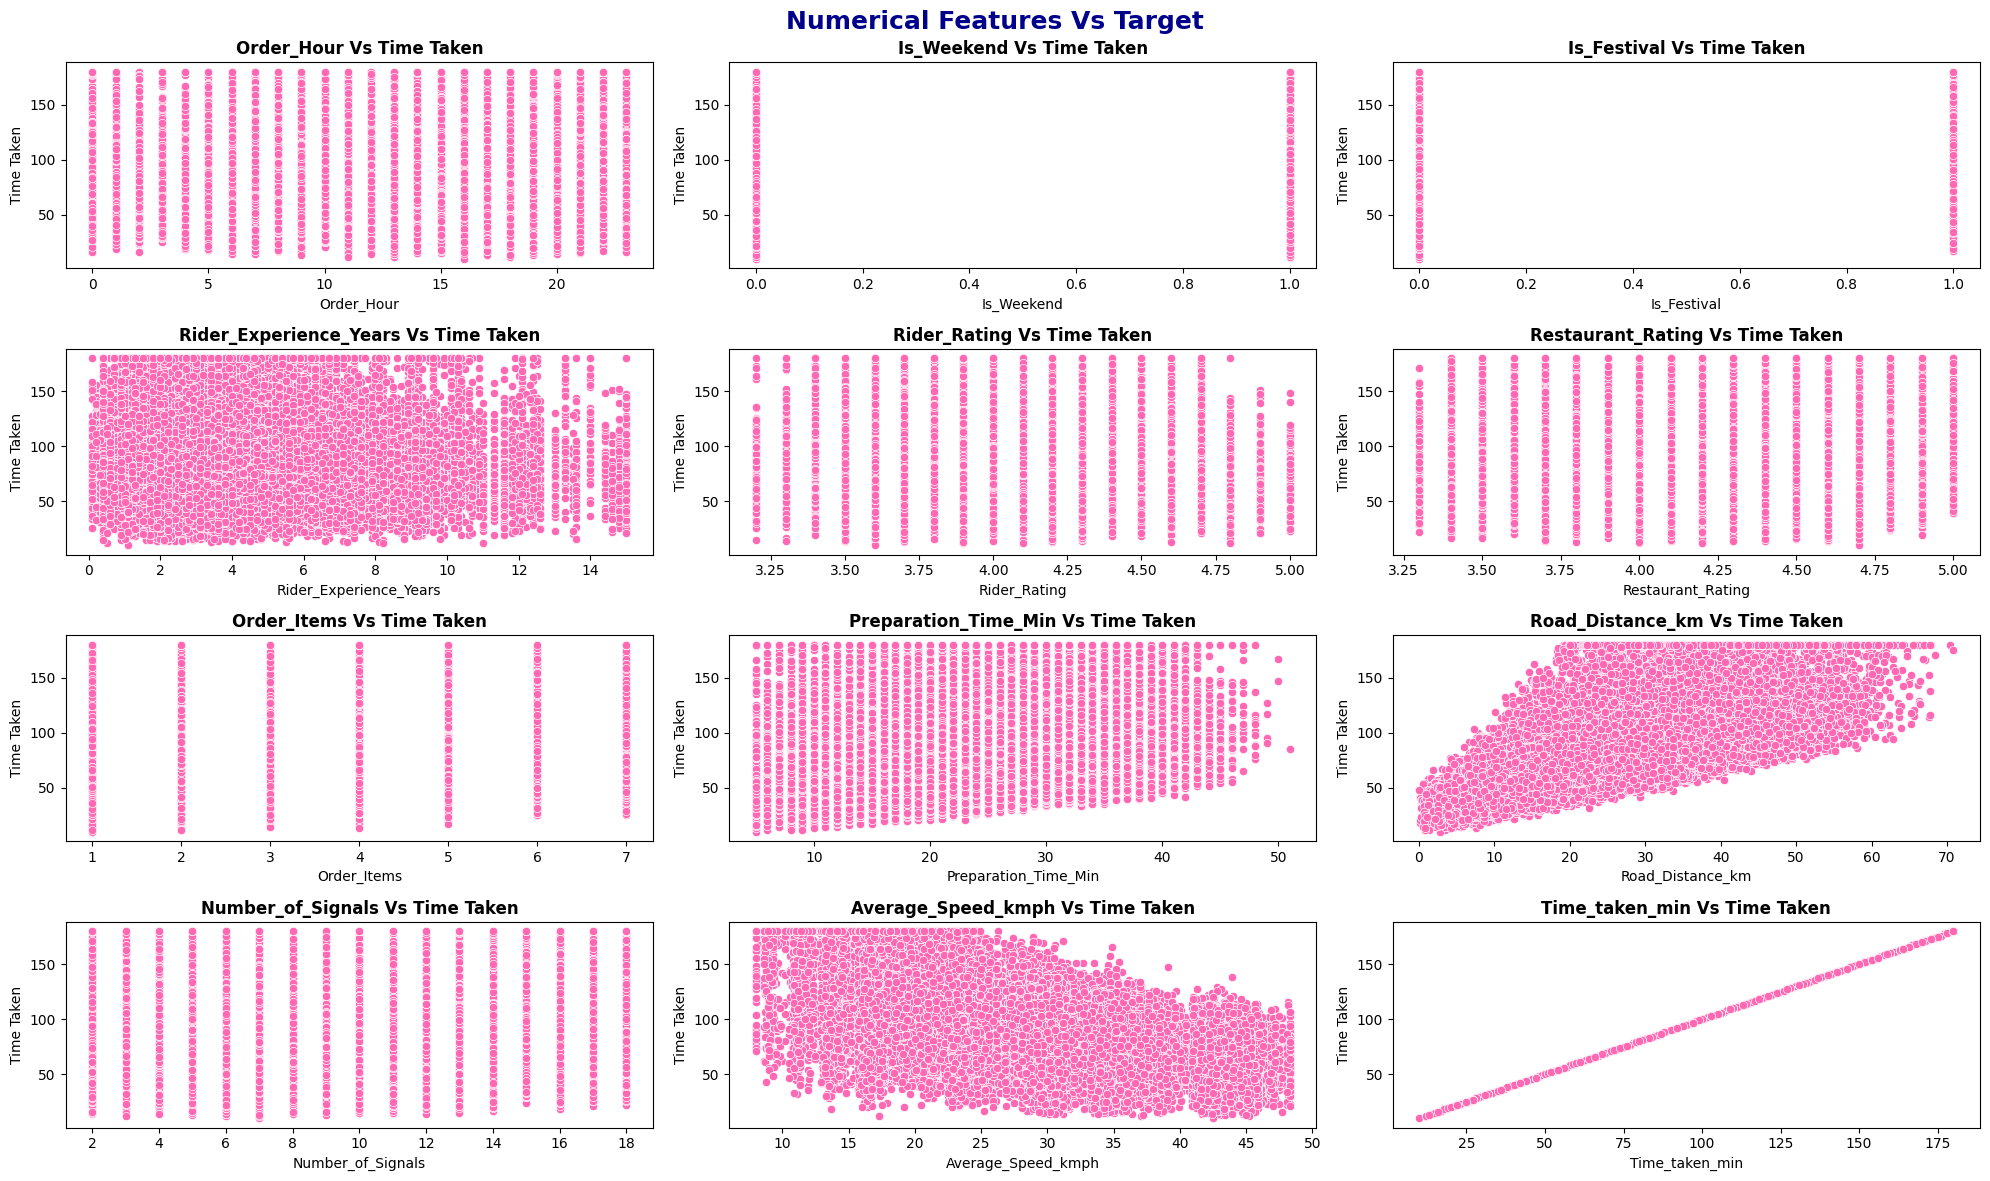

In [14]:
# Numerical vs target 
cols = ['Road_Distance_km','Rider_Experience_Years','Preparation_Time_Min','Average_Speed_kmph']
# categorical conclumns vs Target 
fig , axes = plt.subplots(4,3,figsize =(20,12))
axes = axes.flatten()
plt.suptitle('Numerical Features Vs Target',color = 'darkblue',fontweight = 'bold',fontsize=18)
for i,col in enumerate(num_cols):
    sns.scatterplot(x=data[col],y=data['Time_taken_min'],ax=axes[i],color='hotpink')
    axes[i].set_title(f'{col} Vs Time Taken',fontweight = 'bold')
    axes[i].set_ylabel('Time Taken')
plt.tight_layout()
plt.show()

**Inferance**
- Strongest relationship:  `Road_Distance_km`  shows clear linear positive trend with Time_Taken
- Negative relationship:  `Average_Speed_kmph`  shows negative correlation (higher speed = less time)
- Moderate relationship:  `Preparation_Time_Min`  shows positive trend
- No clear pattern:  `Order_Hour` ,  `Rider_Experience_Years` ,  `Rider_Rating` ,  `Restaurant_Rating` 

Text(0.5, 1.0, 'Correlation Matrix')

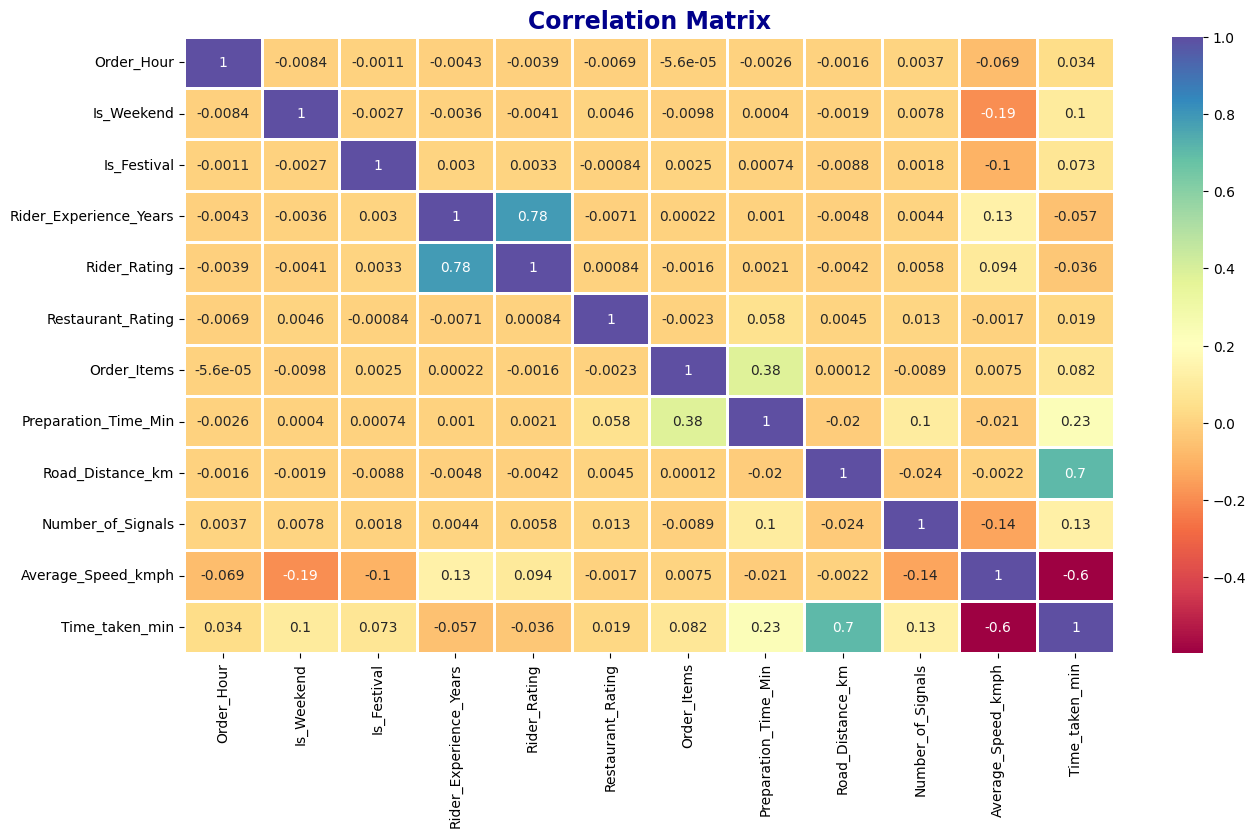

In [15]:
# Feature vs feature
corr_matrix = data.select_dtypes(include='number').corr()
plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix,annot=True,cmap='Spectral',linewidths=0.9)
plt.title('Correlation Matrix',fontdict=dict(fontsize = 17,fontweight = 'bold'),color= 'darkblue')

**Inferance**
- Strongest positive:  `Road_Distance_km`  (0.7) with target
- Strongest negative:  `Average_Speed_kmph`  (-0.6) with target
- ⚠️ Multicollinearity alert:  `Rider_Experience_Years`  and  `Rider_Rating`  have 0.78 correlation - they're measuring similar things
- Moderate:  `Preparation_Time_Min`  (0.23),  `Order_Items`  (0.082)

In [16]:
# Rider-experience and Rider rating are strongly correlated .keeping only rider rating.
data = data.drop(columns=['Rider_Experience_Years'])

## **Feature Engineering**
1. `hour_order` ---> `Time_period`(morning ,evening)

In [17]:
#  M:6am-12pm , A: 12pm-4pm ,E: 4pm-9pm ,N:9pm-6pm  
data['Time_period'] = np.where(data['Order_Hour']<12,'Morning',
                               np.where(data['Order_Hour']<16,'Afternoon',
                                        np.where(data['Order_Hour']<21,'Evening','Night')))

<Axes: xlabel='Time_period', ylabel='Time_taken_min'>

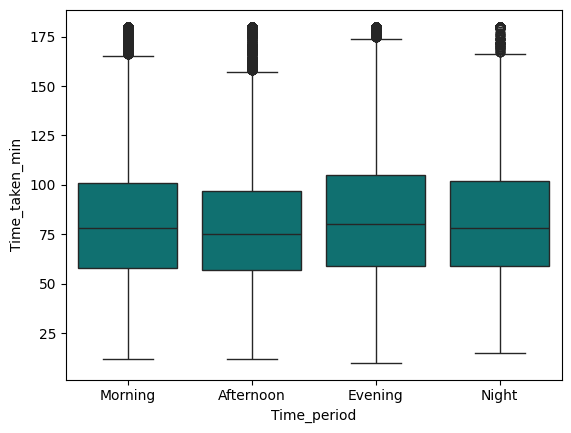

In [18]:
sns.boxplot(x=data['Time_period'],y=data['Time_taken_min'],color='teal')

In [19]:
data = data.drop(columns = ['Order_Hour'])

 **<h3>Removing low-value & data leakage features**</h3>
- `Day_of_week`,`Restaurant_load` `Delivery_priority`,`Restaurant_rating` show minimal variation in delivery time.

In [20]:
data.drop(columns=['Day_of_Week','Restaurant_Load','Delivery_Priority','Restaurant_Rating'],inplace=True)
# data leakage features 
data =data.drop(columns = ['Preparation_Time_Min', 'Average_Speed_kmph',])

In [21]:
data.columns

Index(['Is_Weekend', 'Is_Festival', 'Weather', 'Pickup_Zone', 'Dropoff_Zone',
       'Vehicle_Type', 'Rider_Rating', 'Cuisine_Type', 'Order_Items',
       'Road_Distance_km', 'Delivery_Distance_Category', 'Traffic_Level',
       'Number_of_Signals', 'Time_taken_min', 'Time_period'],
      dtype='str')

In [22]:
print(data['Vehicle_Type'].unique().tolist())

['Scooter', 'Bike', 'Electric Scooter', 'Bicycle']


In [23]:
## computed field...
# 'Delivery_Distance_Category','Time_period'

In [24]:
data.shape

(50000, 15)

## **Spilitting data in x and y**

In [25]:
x = data.drop(columns=['Time_taken_min'])
y = data['Time_taken_min']

In [26]:
cat_cols  = x.select_dtypes(include='str').columns.to_list()
ord_cols = ['Traffic_Level','Delivery_Distance_Category']
nom_cols = [cols for cols in cat_cols if cols not in ord_cols]

In [27]:
# split in train test split
x_train , x_test ,y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

## **Pipeline**

In [28]:
preprocessor = ColumnTransformer(transformers=[
    ('ohe',OneHotEncoder(handle_unknown='ignore',drop='first',sparse_output=False),nom_cols),
    ('oe',OrdinalEncoder(categories=[['Low','Moderate','High','Severe'],['Short','Medium','Long']]),ord_cols)
],remainder='passthrough')

In [29]:
rf_pipe = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('model',RandomForestRegressor(random_state=42))
])

In [30]:
rf_pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...), ('oe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

In [31]:
y_pred = rf_pipe.predict(x_test)

In [32]:
rf_pipe.score(x_train,y_train)

0.996181275813279

In [33]:
print('MSE:',mean_absolute_error(y_test,y_pred))
print('RMSE: ',root_mean_squared_error(y_test,y_pred))
print('R2_Score: ',r2_score(y_test,y_pred))

MSE: 4.450495
RMSE:  5.785121503477693
R2_Score:  0.9736523752862855


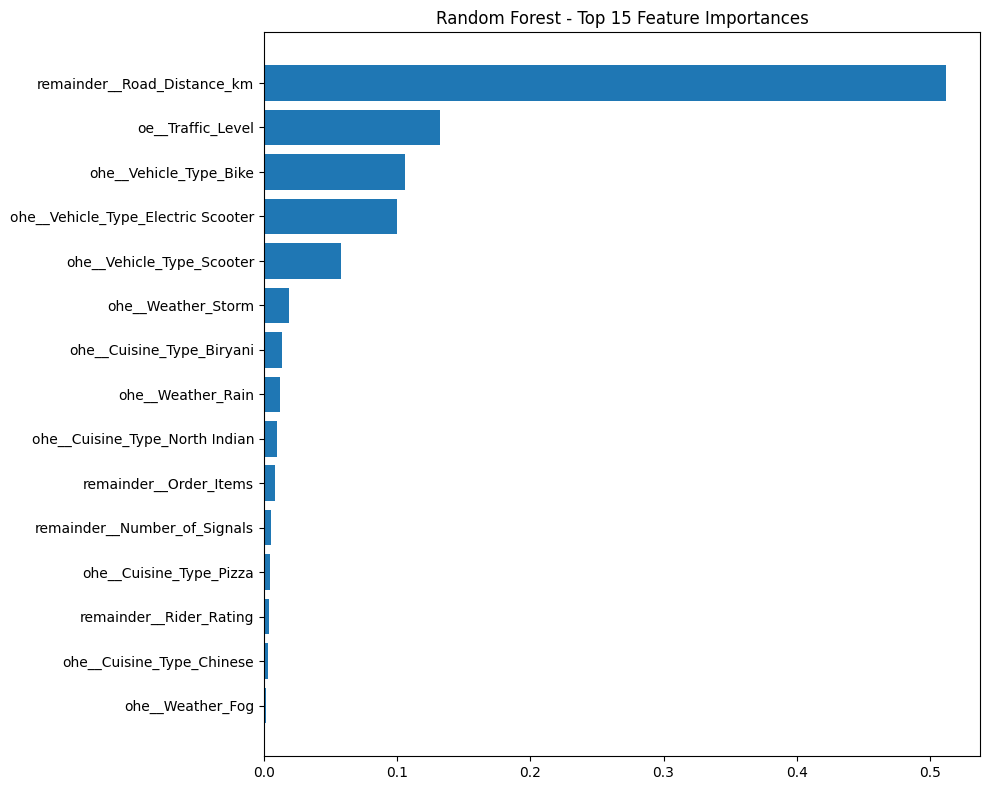

In [34]:
# Get feature names from preprocessor
feature_names = rf_pipe[:-1].get_feature_names_out()

# Get feature importances from the Random Forest model
importances = rf_pipe.named_steps['model'].feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'][:15], 
         feature_importance_df['Importance'][:15])
plt.gca().invert_yaxis()
plt.title('Random Forest - Top 15 Feature Importances')
plt.tight_layout()
plt.show()

In [35]:
from xgboost import XGBRegressor

In [36]:
xgb_pipe = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('model',XGBRegressor(random_state=42))
])

In [37]:
xgb_pipe.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...), ('oe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

In [38]:
y_pred = xgb_pipe.predict(x_test)

In [39]:
print('MSE:',mean_absolute_error(y_test,y_pred))
print('RMSE: ',root_mean_squared_error(y_test,y_pred))
print('R2_Score: ',r2_score(y_test,y_pred))

MSE: 3.977293014526367
RMSE:  5.059140682220459
R2_Score:  0.9798502326011658


## **Shuffle split**

In [40]:
from sklearn.model_selection import ShuffleSplit ,cross_val_score

In [41]:
cv = ShuffleSplit(n_splits=3,test_size=0.2,random_state=42)
np.mean(cross_val_score(xgb_pipe,x_train,y_train,cv=cv,scoring='r2',n_jobs=-1))

np.float64(0.9795225660006205)

In [42]:
# save model
import joblib
joblib.dump(xgb_pipe,'xgb_model')

['xgb_model']